# Phase 1: Data Understanding and Descriptive Statistics
**NHANES 2021–2023: sleep duration, physical activity, HbA1c, and BMI among U.S. adults** (Track A)

This notebook walks through Phase 1. The analysis code lives in `src/` (scripts `01`–`06`) so that every step is reproducible from the command line; the notebook runs those scripts, displays their tables and figures, and records the reasoning behind each decision. Run all cells from top to bottom. The full write-up is in `reports/phase1/phase1_report.pdf`.

### Where to find each task

| Task | Section |
|---|---|
| 1–2 Data origin, unit of observation; A.1 files and merge key | 1 |
| 3–4 Sampling and generalizability; classification of variables | 1b |
| 5 Data-quality audit; A.4 analytic population | 2, 3 |
| 6–7 Frequency tables; center and spread | 4 |
| A.2–A.3 Sampling weights; unweighted vs. weighted summaries | 5 |
| 8 Graphical summaries | 6 |
| 9 Preliminary descriptive comparison | 7 |
| 10 Final statistical question | 8 |

In [13]:
import io
import runpy
import sys
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
TABLES = ROOT / "reports" / "phase1" / "tables"
FIGS = ROOT / "figures" / "phase1"
PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(SRC))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def run_step(name, show_output=True):
    """Run one pipeline script from src/ exactly as `python src/<name>.py` would."""
    buffer = io.StringIO()
    try:
        with redirect_stdout(buffer):
            runpy.run_path(str(SRC / f"{name}.py"), run_name="__main__")
    finally:
        if show_output:
            print(buffer.getvalue())


def show_table(name):
    display(pd.read_csv(TABLES / f"{name}.csv"))

## 1. Data source, unit of observation, and merge (tasks 1–2, A.1)

NHANES is a cross-sectional survey run by NCHS/CDC: an interview plus a standardized examination and laboratory tests. We use six public files from the August 2021 – August 2023 cycle: `DEMO_L` (demographics, weights, design variables), `GHB_L` (HbA1c), `SLQ_L` (sleep), `PAQ_L` (physical activity), `BMX_L` (body measures), and `DIQ_L` (diabetes).

One row is one participant (`SEQN`); there are no repeated measurements. `DEMO_L` contains every participant, so it is the base of the merge, and the other files are attached with one-to-one left joins on `SEQN`.

In [14]:
run_step("01_load_merge")
show_table("merge_counts")

Participants per file (before merging):
  file  n_rows  n_unique_seqn  n_seqn_found_in_demo  n_columns
DEMO_L   11933          11933                 11933         27
 GHB_L    7199           7199                  7199          3
 PAQ_L    8153           8153                  8153          8
 SLQ_L    8501           8501                  8501          7
 BMX_L    8860           8860                  8860         22
 DIQ_L   11744          11744                 11744          9

After merging: 11933 participants, 71 columns
Saved merged file and count table.



,file,n_rows,n_unique_seqn,n_seqn_found_in_demo,n_columns
0,DEMO_L,11933,11933,11933,27
1,GHB_L,7199,7199,7199,3
2,PAQ_L,8153,8153,8153,8
3,SLQ_L,8501,8501,8501,7
4,BMX_L,8860,8860,8860,22
5,DIQ_L,11744,11744,11744,9


**Result.** All six files have unique `SEQN` values and all of them appear in `DEMO_L`. The merge keeps 11,933 participants, and the merged file has 71 columns (76 minus five duplicated `SEQN` columns). Participants differ in which components they have: for example `BMX_L` exists only for examined participants and `GHB_L` only for those with an eligible blood draw.

## 1b. Sampling, selection, generalizability, and variable classification (tasks 3–4)

Task 3: sampling, selection, and generalizability. NHANES uses a stratified, multistage cluster probability sample of the U.S. civilian noninstitutionalized population, so participants have unequal probabilities of selection. According to the DEMO_L documentation, this cycle oversampled by age group, and not by race/Hispanic origin or income. Selection into our analysis has three layers: (i) the survey sample itself; (ii) examination, since 6,064 of 7,809 adults (77.7%) were examined in the mobile examination center; and (iii) availability of all key variables, since 5,490 of 6,023 eligible non-pregnant adults have complete data. The study is observational, so associations cannot be interpreted causally. Weighted results can be generalized to U.S. civilian noninstitutionalized adults aged 20 years or older in 2021–2023 (subject to nonresponse and the complete-case restriction), whereas unweighted results describe the analytic sample only.

Task 4: classification of variables.

| Variable | Description | Type / scale | Role |
|---|---|---|---|
| LBXGH | HbA1c (%) | Quantitative, continuous | Response (primary) |
| BMXBMI | Body mass index (kg/m²) | Quantitative, continuous | Response (secondary); adjustment variable |
| sleep_hours | Weekly average sleep, h/day (derived from SLD012, SLD013) | Quantitative, continuous | Explanatory |
| mvpa_min_week | Leisure-time moderate + vigorous activity, min/week (derived from PAQ_L) | Quantitative, continuous, right-skewed | Explanatory |
| sedentary_hours | Usual daily sitting time, hours (PAD680 / 60) | Quantitative, continuous | Explanatory |
| RIDAGEYR | Age in years (top-coded at 80) | Quantitative, discrete | Adjustment |
| RIAGENDR | Sex | Nominal, binary | Adjustment |
| RIDRETH3 | Race and Hispanic origin | Nominal | Adjustment |
| DIQ010 | Diagnosed diabetes (yes / no / borderline) | Nominal | Stratification / sensitivity |
| sleep_cat, mvpa_cat, bmi_cat, age_group | Categorized sleep, activity, BMI, and age | Ordinal (derived) | Grouping (descriptive, ANOVA) |
| WTPH2YR, SDMVSTRA, SDMVPSU | Phlebotomy weight; masked variance stratum; masked PSU | Quantitative / design identifiers | Survey design |

## 2. Cleaning, derived variables, and the analytic population (task 5, A.4)

Decisions made in `src/02_build_analytic_dataset.py`:

- Refused (7777) and don't-know (9999) codes are set to missing.
- SAS stores zeros as a tiny number (about 5e-79). These are real zeros (no activity, no sitting) and are converted to 0.
- Weekly activity minutes = frequency × occasions per week × minutes per occasion (a frequency of 0 means 0 minutes). Weekly average sleep = (5 × workday sleep + 2 × non-workday sleep) / 7.
- Inclusion: age ≥ 20, examined in the MEC, not pregnant, and non-missing HbA1c (with a positive phlebotomy weight), BMI, sleep, activity, and sedentary time.

In [15]:
run_step("02_build_analytic_dataset")

Special codes set to missing:
variable        codes  n_set_to_missing
 PAD790Q [7777, 9999]                49
  PAD800 [7777, 9999]                19
 PAD810Q [7777, 9999]                40
  PAD820 [7777, 9999]                14
  PAD680 [7777, 9999]                73
  DIQ010       [7, 9]                 4
DMDEDUC2       [7, 9]                11

Sample flow:
                                      step  n_remaining  n_removed
All NHANES 2021-2023 participants (DEMO_L)        11933          0
                           Age >= 20 years         7809       4124
       Examined in the MEC (RIDSTATR == 2)         6064       1745
              Not pregnant (RIDEXPRG != 1)         6023         41
HbA1c available with phlebotomy weight > 0         5730        293
                             BMI available         5649         81
           Weekly sleep duration available         5571         78
               Leisure-time MVPA available         5514         57
                  Sedentary time 

In [16]:
sample = pd.read_csv(PROCESSED / "analytic_sample.csv")
print("Analytic sample:", sample.shape[0], "adults")
sample[["SEQN", "RIDAGEYR", "LBXGH", "BMXBMI", "sleep_hours", "mvpa_min_week", "sedentary_hours", "WTPH2YR"]].head()

Analytic sample: 5490 adults


,SEQN,RIDAGEYR,LBXGH,BMXBMI,sleep_hours,mvpa_min_week,sedentary_hours,WTPH2YR
0,130378,43.0,5.6,27.0,9.357143,270.000000,6.0,56042.129410
1,130379,66.0,5.6,33.5,9.000000,315.000000,8.0,37435.705647
2,130380,44.0,6.2,29.7,8.285714,20.000000,4.0,85328.844519
3,130386,34.0,5.1,30.2,7.642857,36.923077,3.0,44526.214135
4,130387,68.0,5.9,42.6,3.571429,0.000000,20.0,22746.296353


## 3. Data quality audit (task 5)

Missingness is audited among the 6,023 adults who were examined and not pregnant; range, plausibility, and consistency checks use the analytic sample.

In [17]:
run_step("03_quality_and_descriptives", show_output=False)
show_table("missingness_adults")
show_table("quality_checks")

,variable,description,n_total,n_missing,pct_missing
0,LBXGH,HbA1c (%),6023,293,4.86
1,BMXBMI,BMI (kg/m^2),6023,94,1.56
2,sleep_hours,Weekly average sleep (h/day),6023,86,1.43
3,mvpa_min_week,Leisure-time MVPA (min/week),6023,70,1.16
4,sedentary_hours,Sedentary time (h/day),6023,44,0.73
5,INDFMPIR,Income-to-poverty ratio,6023,787,13.07
6,DMDEDUC2,Education level,6023,4,0.07
7,DIQ010,Diagnosed diabetes,6023,0,0.00


,check,n_flagged
0,Duplicate SEQN in adult file,0
1,HbA1c outside 3-18 % (analytic sample),0
2,BMI outside 10-80 kg/m^2 (analytic sample),0
3,Sleep < 3 h or > 12 h per day (analytic sample),63
4,Sedentary time = 0 min (analytic sample),3
5,Sedentary time >= 18 h (CAPI soft-edit threshold),22
6,MVPA > 2520 min/week (avg > 6 h/day),48
7,"MVPA > 10080 min/week (impossible, > 24 h/day)",0
8,Moderate frequency > 0 but unit missing (adults),0
9,Vigorous frequency > 0 but unit missing (adults),0


**Decisions.**

- HbA1c has 4.9% missing (no eligible blood sample); the other key variables have about 1% each. We use complete cases and note that the weights were not re-adjusted for this extra nonresponse.
- Implausible but in-range values (sleep < 3 h or > 12 h: 63; sitting time 0 min: 3 or ≥ 18 h: 22; leisure-time activity > 2,520 min/week: 48) are **kept and flagged**. There is no prespecified scientific rule for deleting them. Phase 5 repeats the analysis without them.
- 41 pregnant participants are excluded because pregnancy affects BMI and HbA1c.
- The income-to-poverty ratio is missing for 13.1% of adults, so it is not used in the primary models.
- No duplicate `SEQN` and no logical inconsistencies were found.

## 4. Frequency tables, center, and spread (tasks 6–7)

In [18]:
show_table("frequency_tables")
show_table("numeric_summary")

,variable,category,n,percent
0,sex,Male,2474,45.1
1,sex,Female,3016,54.9
2,age_group,20-39,1364,24.8
3,age_group,40-59,1610,29.3
4,age_group,60+,2516,45.8
5,race_eth,Non-Hispanic Asian,307,5.6
6,race_eth,Non-Hispanic White,3294,60.0
7,race_eth,Other Hispanic,555,10.1
8,race_eth,Mexican American,369,6.7
9,race_eth,Non-Hispanic Black,620,11.3


,variable,n,mean,sd,min,q1,median,q3,max,iqr,range,skewness
0,RIDAGEYR,5490,54.00,16.96,20.0,40.00,57.00,68.00,80.0,28.00,60.0,-0.29
1,LBXGH,5490,5.78,1.09,3.2,5.20,5.50,5.90,17.1,0.70,13.9,3.56
2,BMXBMI,5490,29.83,7.27,14.1,24.70,28.50,33.58,74.8,8.88,60.7,1.23
3,sleep_hours,5490,7.85,1.47,2.0,7.00,8.00,8.64,14.0,1.64,12.0,-0.16
4,mod_min_week,5490,220.10,394.47,0.0,20.77,120.00,240.00,6300.0,219.23,6300.0,5.78
5,vig_min_week,5490,68.57,222.48,0.0,0.00,0.00,60.00,6720.0,60.00,6720.0,11.56
6,mvpa_min_week,5490,288.67,514.16,0.0,30.00,148.85,360.00,7200.0,330.00,7200.0,5.65
7,sedentary_hours,5490,6.06,3.46,0.0,3.00,5.00,8.00,23.0,5.00,23.0,0.78
8,INDFMPIR,4803,2.98,1.64,0.0,1.48,2.92,5.00,5.0,3.52,5.0,-0.09


**Interpretation.** HbA1c (skewness 3.56) and weekly leisure-time activity (skewness 5.65) are strongly right-skewed: the median and IQR describe a typical adult better than the mean and SD. BMI is moderately right-skewed (1.23). Sleep is nearly symmetric (−0.16), so the mean and SD are appropriate. The analytic sample is 54.9% female and 45.8% aged 60 or older, 41.0% have obesity, and 14.0% report diagnosed diabetes.

## 5. Sampling weights and unweighted vs. weighted summaries (A.2, A.3)

NHANES is a complex probability sample, and each participant's weight is the number of people in the target population that he or she represents. Because HbA1c is a blood analyte, the analysis uses the phlebotomy weight `WTPH2YR` (GHB_L documentation). This cycle oversampled by age group, so older adults are overrepresented in the sample.

In [19]:
run_step("04_weights_and_weighted_summaries", show_output=False)
show_table("weight_summary")
show_table("weights_by_group")

,weight,n,min,median,max,max_to_min_ratio,sum_millions,cv,kish_design_effect,effective_n
0,WTPH2YR,5490,4391.82,33515.62,241728.86,55.04,233.03,0.74,1.55,3552.45
1,WTMEC2YR,5490,4581.60,32036.35,227108.30,49.57,222.60,0.73,1.53,3598.15


,variable,group,n,mean_weight,population_millions,pct_of_sample,pct_of_population
0,age_group,20-39,1364,59688.0,81.4,24.8,34.9
1,age_group,40-59,1610,49361.0,79.5,29.3,34.1
2,age_group,60+,2516,28676.0,72.1,45.8,31.0
3,race_eth,Mexican American,369,45057.0,16.6,6.7,7.1
4,race_eth,Non-Hispanic Asian,307,47555.0,14.6,5.6,6.3
5,race_eth,Non-Hispanic Black,620,39742.0,24.6,11.3,10.6
6,race_eth,Non-Hispanic White,3294,42875.0,141.2,60.0,60.6
7,race_eth,Other / multiracial,345,39948.0,13.8,6.3,5.9
8,race_eth,Other Hispanic,555,39923.0,22.2,10.1,9.5
9,sex,Female,3016,39406.0,118.8,54.9,51.0


In [20]:
w = sample["WTPH2YR"]
print("Unweighted mean age:", round(sample["RIDAGEYR"].mean(), 2))
print("Weighted mean age:  ", round(np.average(sample["RIDAGEYR"], weights=w), 2))
print("Population represented (millions):", round(w.sum() / 1e6, 1))
print("Effective sample size:", round(w.sum() ** 2 / (w ** 2).sum()))

Unweighted mean age: 54.0
Weighted mean age:   48.83
Population represented (millions): 233.0
Effective sample size: 3552


In [21]:
show_table("raw_vs_weighted_numeric")
show_table("raw_vs_weighted_categorical")

,variable,raw_mean,weighted_mean,raw_median,weighted_median,raw_sd,weighted_sd,mean_difference
0,RIDAGEYR,54.00,48.83,57.00,48.0,16.96,17.32,-5.18
1,LBXGH,5.78,5.71,5.50,5.5,1.09,1.09,-0.08
2,BMXBMI,29.83,29.70,28.50,28.3,7.27,7.25,-0.13
3,sleep_hours,7.85,7.86,8.00,8.0,1.47,1.41,0.01
4,mvpa_min_week,288.67,301.21,148.85,150.0,514.16,528.10,12.53
5,sedentary_hours,6.06,6.10,5.00,5.0,3.46,3.48,0.04


,variable,category,raw_pct,weighted_pct,difference_pp
0,sex,Female,54.9,51.0,-3.9
1,sex,Male,45.1,49.0,3.9
2,age_group,20-39,24.8,34.9,10.1
3,age_group,40-59,29.3,34.1,4.8
4,age_group,60+,45.8,31.0,-14.9
5,race_eth,Mexican American,6.7,7.1,0.4
6,race_eth,Non-Hispanic Asian,5.6,6.3,0.7
7,race_eth,Non-Hispanic Black,11.3,10.6,-0.7
8,race_eth,Non-Hispanic White,60.0,60.6,0.6
9,race_eth,Other / multiracial,6.3,5.9,-0.4


**Interpretation.** Age shows the largest difference (unweighted mean 54.0 vs. weighted 48.8 years; adults aged 60+ are 45.8% of the sample but 31.0% of the weighted population). Diagnosed diabetes is 14.0% unweighted and 11.5% weighted. Mean HbA1c, BMI, and sleep change very little. The weights vary by a factor of 55, which gives a design effect of about 1.55 and an effective sample size of about 3,550, so weighted estimates are less precise than the nominal sample size suggests.

## 6. Graphical summaries (task 8)

fig1_hba1c_hist.png


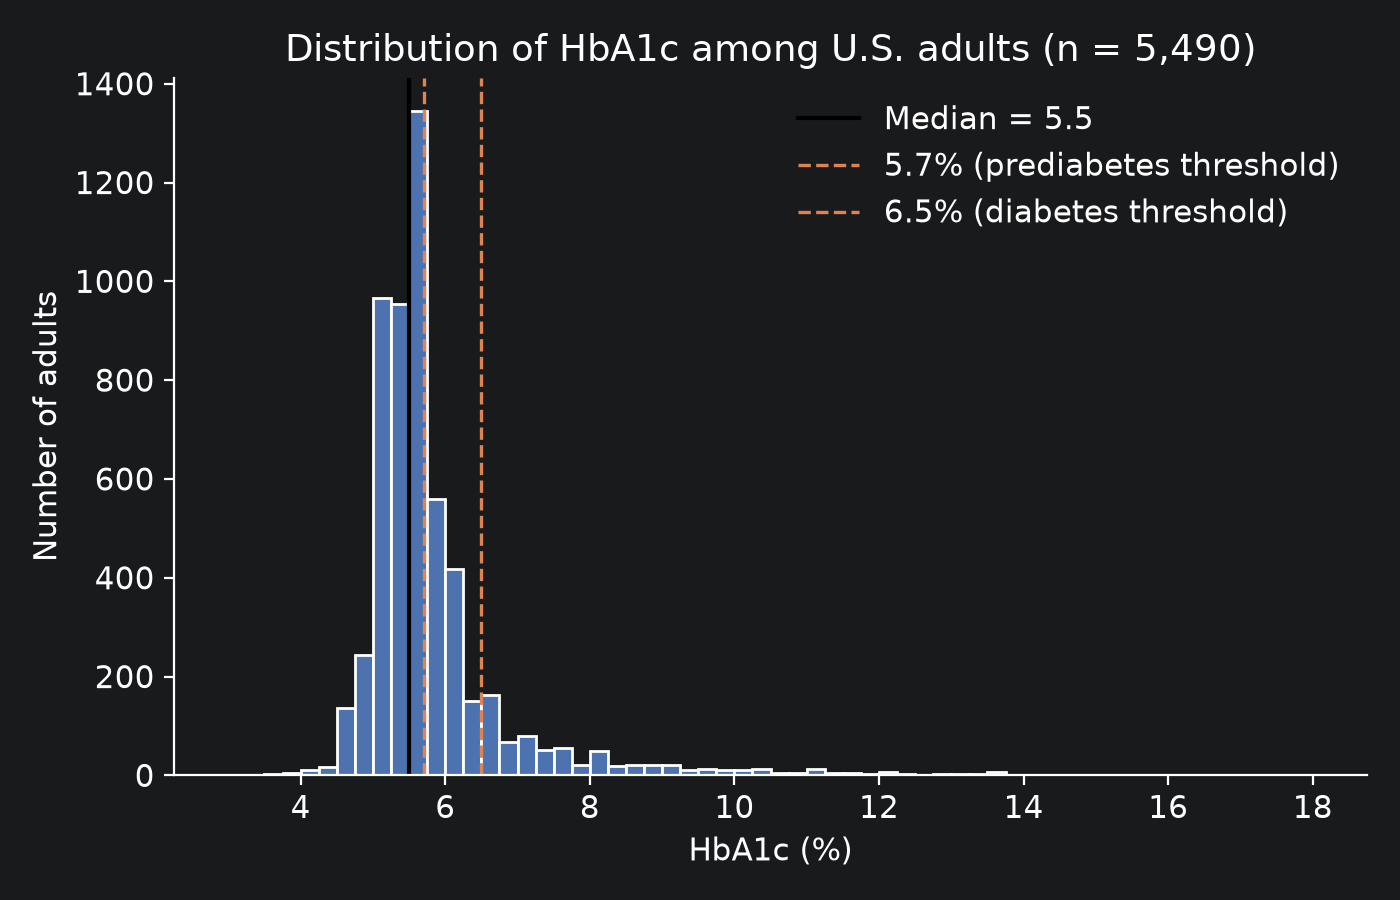

fig2_bmi_hist.png


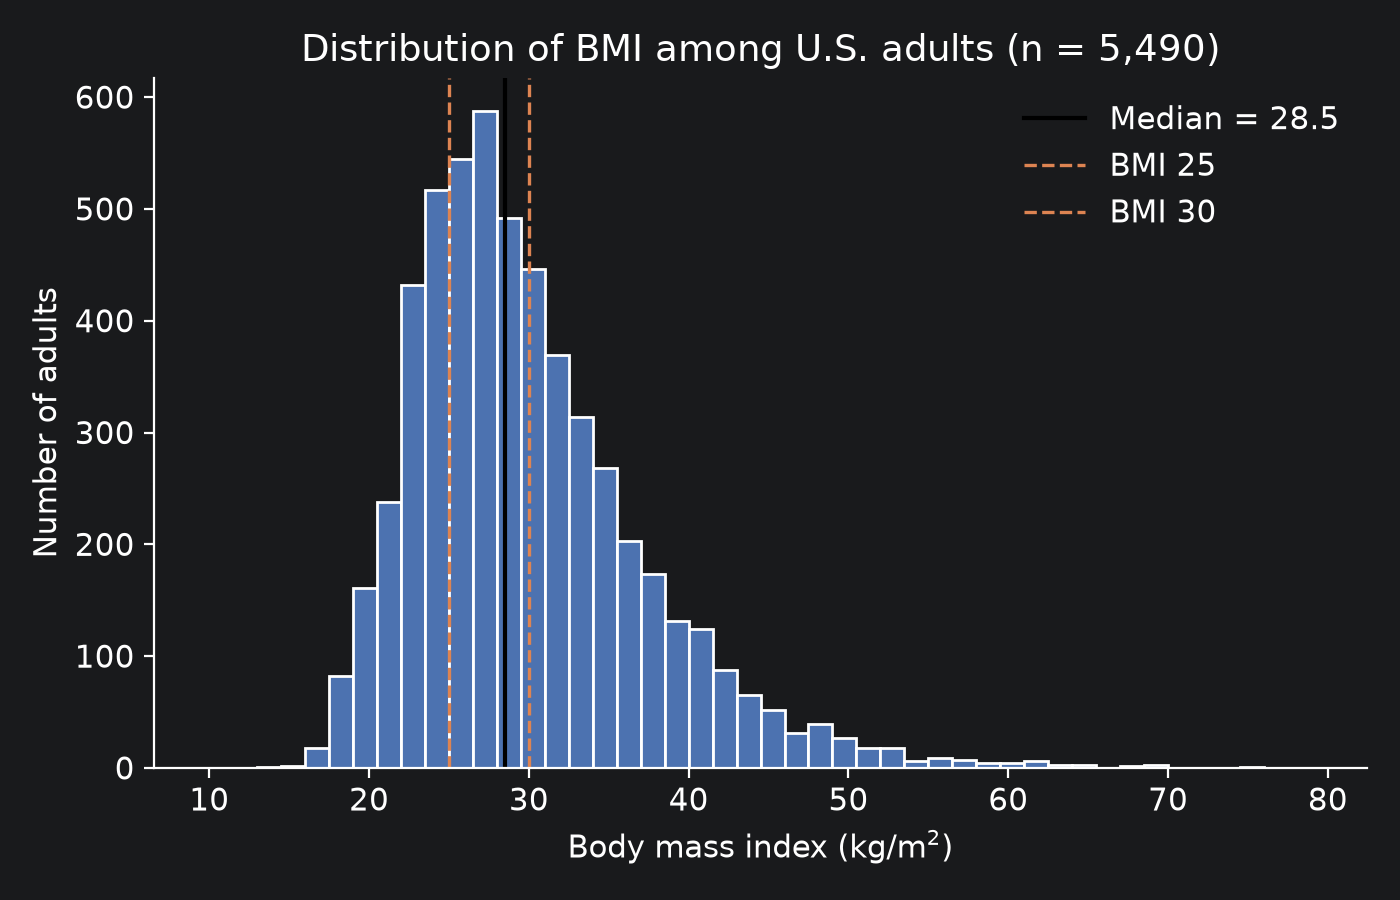

fig3_sleep_hist.png


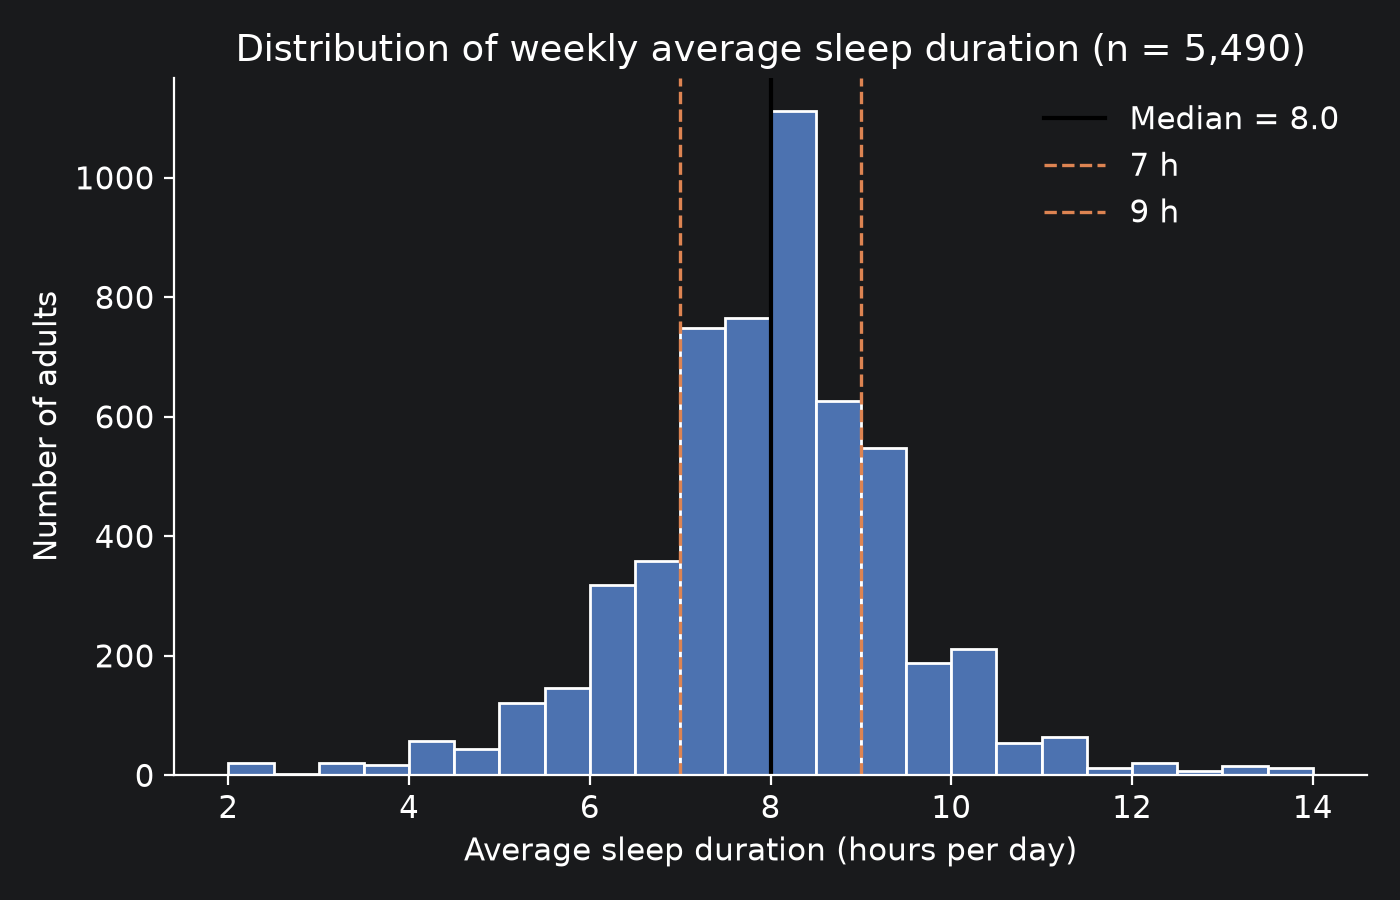

fig4_mvpa_categories.png


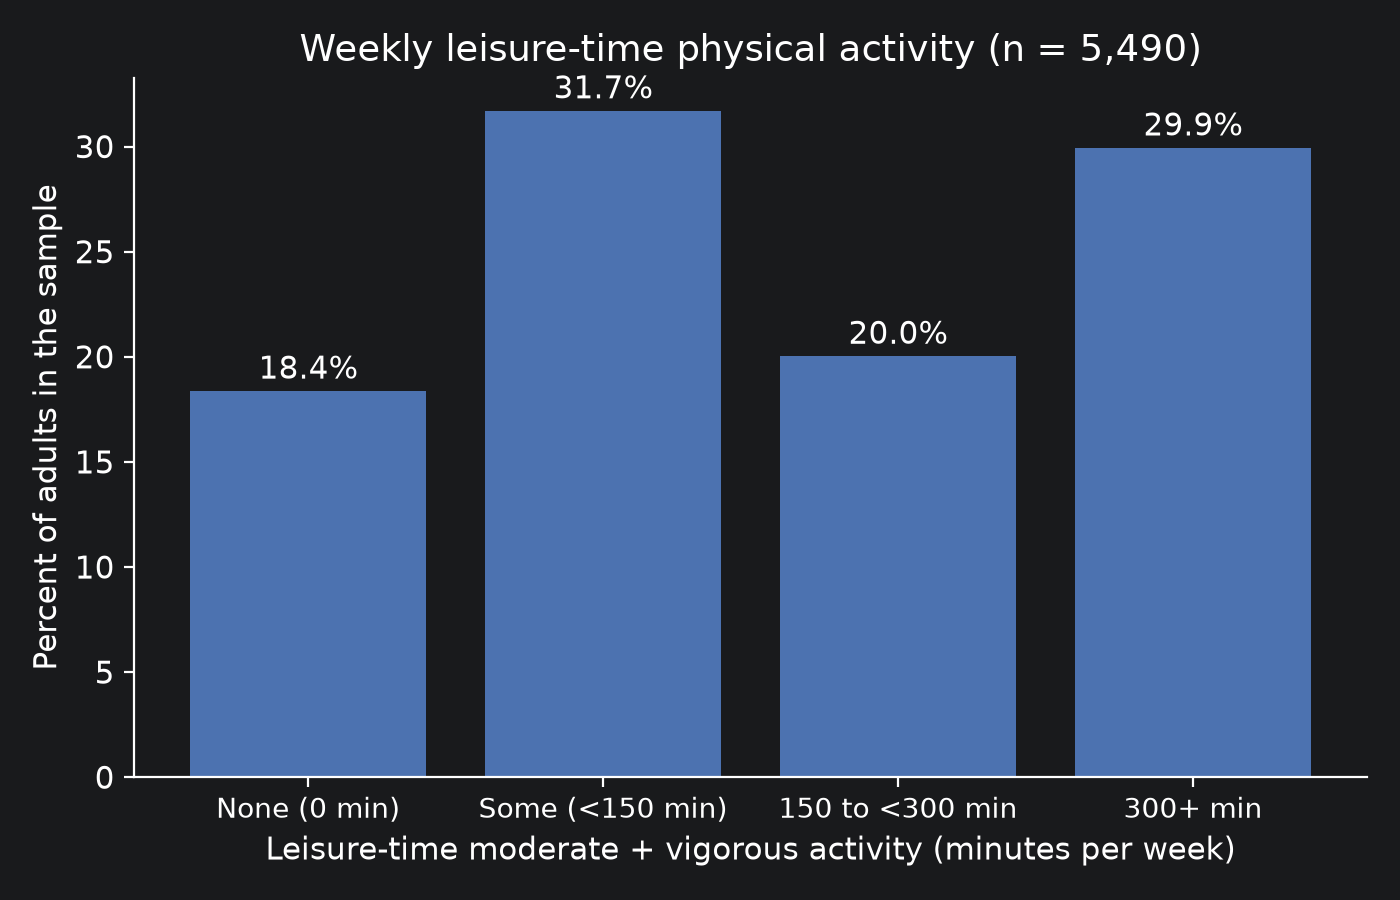

fig5_hba1c_by_sleep.png


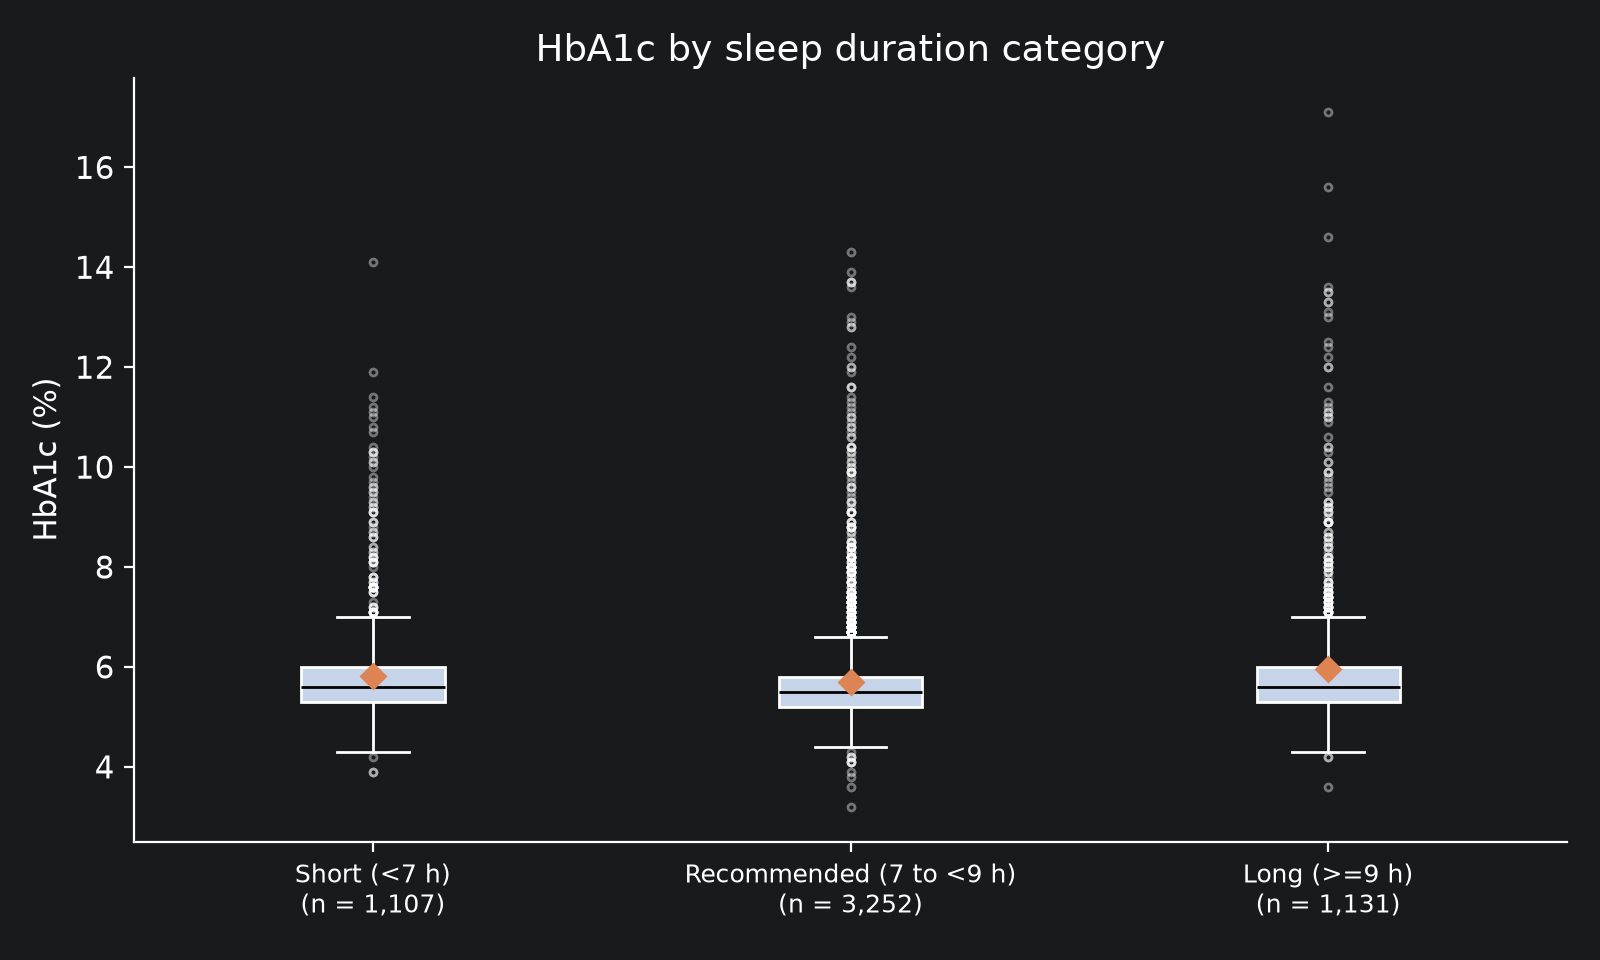

fig6_hba1c_by_bmi.png


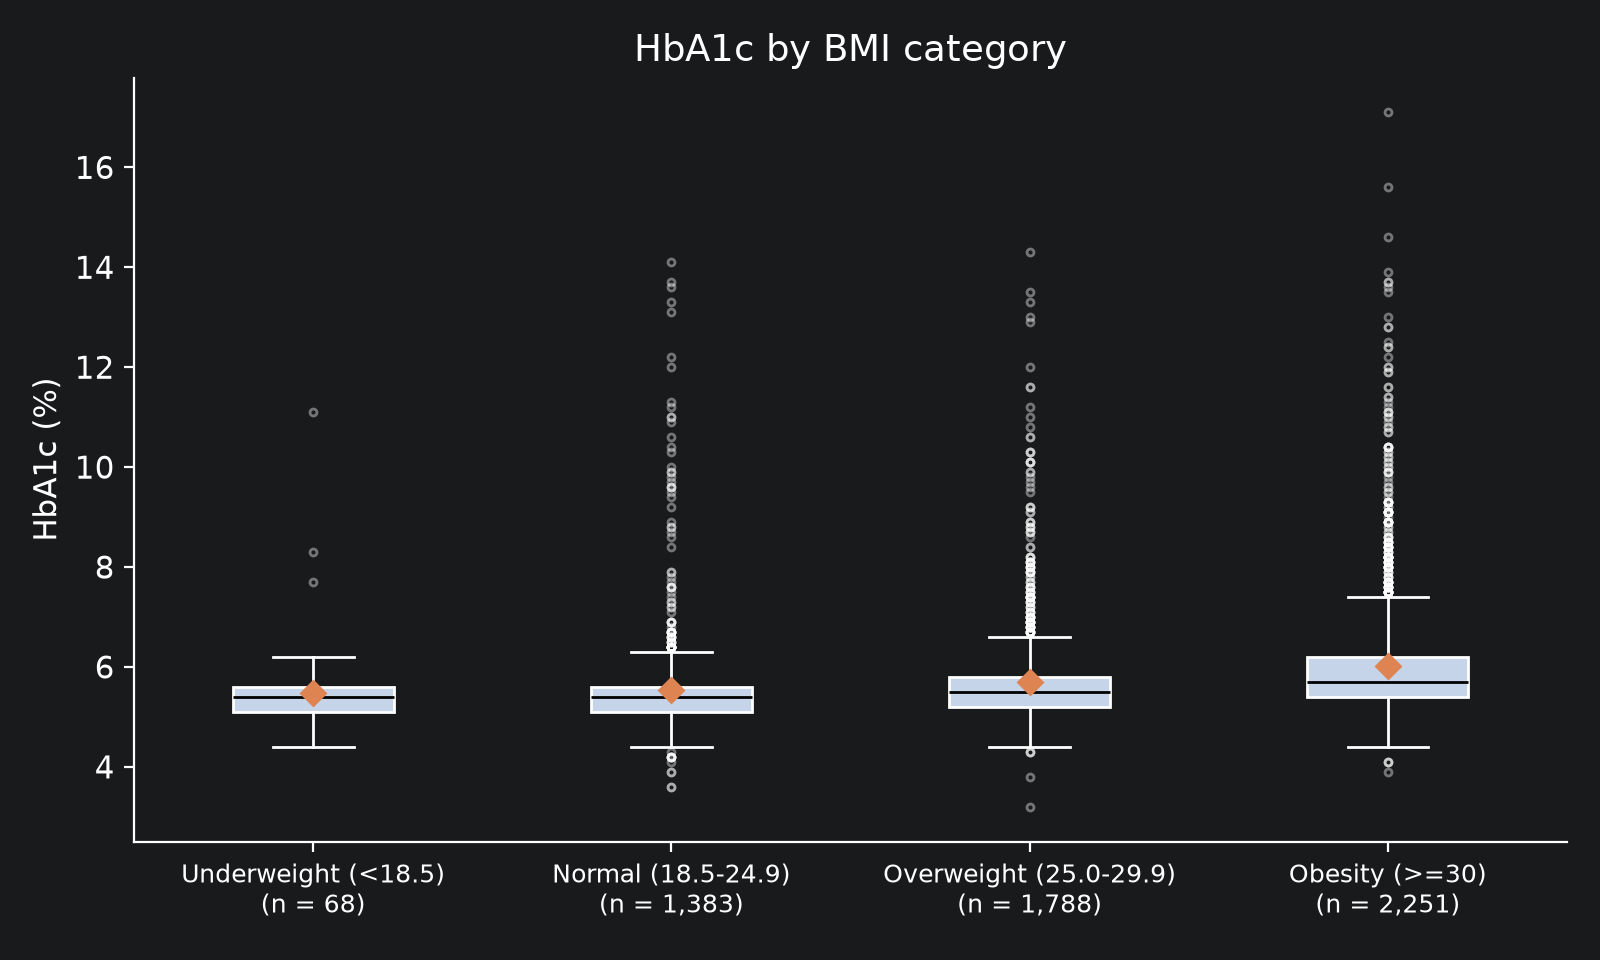

fig7_age_raw_vs_weighted.png


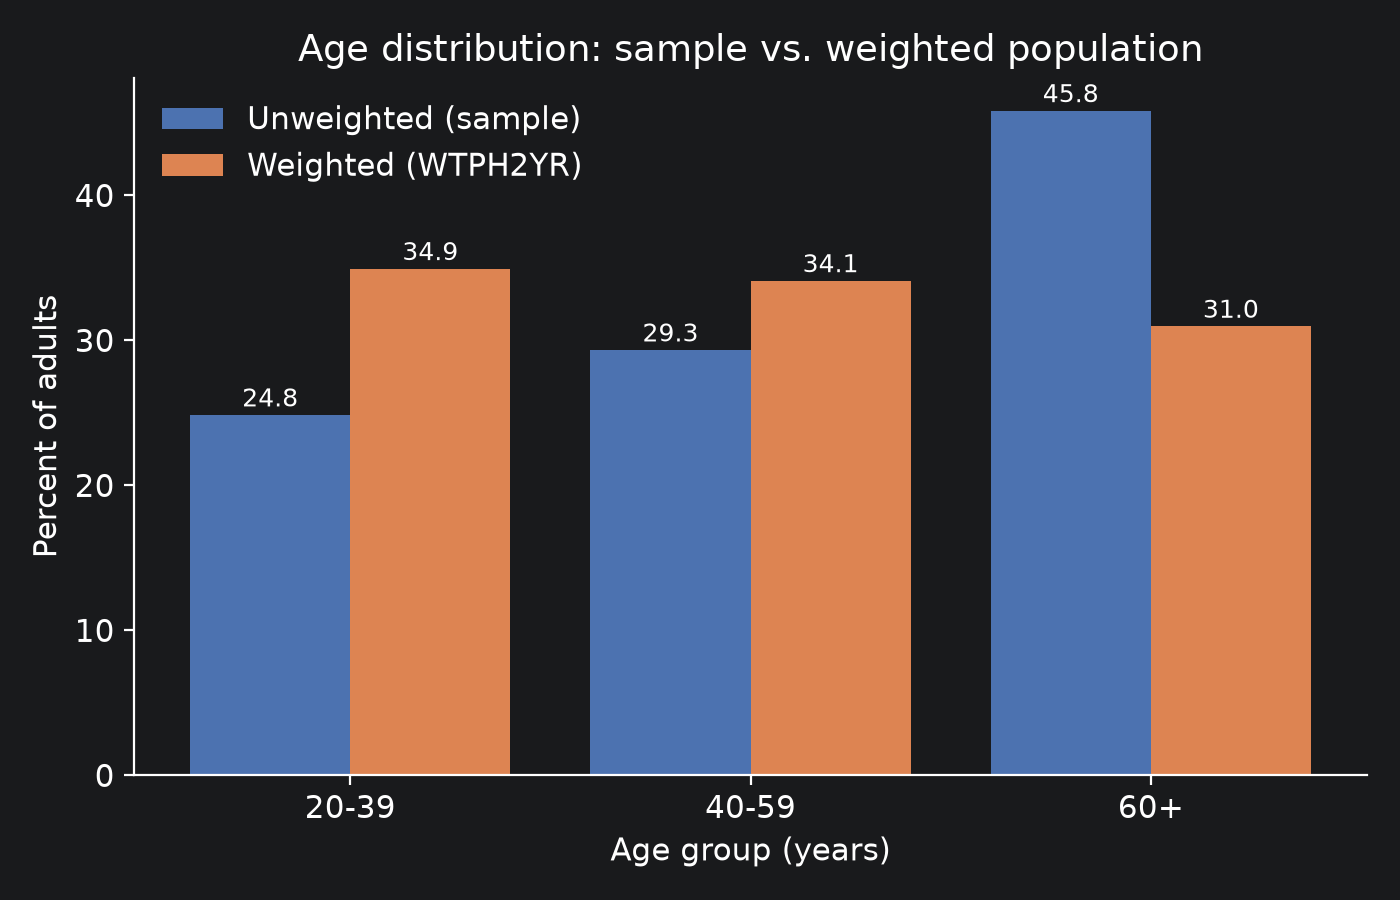

In [22]:
run_step("05_figures_and_group_comparison", show_output=False)
for path in sorted(FIGS.glob("fig*.png")):
    print(path.name)
    display(Image(filename=str(path), width=620))

## 7. Preliminary descriptive comparison (task 9)

These comparisons are purely descriptive: no tests are performed and no inferential claims are made.

In [23]:
show_table("group_comparison")

,group_variable,group,outcome,n,mean,sd,q1,median,q3,weighted_mean
0,sleep_cat,Short (<7 h),LBXGH,1107,5.83,1.03,5.30,5.6,6.00,5.75
1,sleep_cat,Recommended (7 to <9 h),LBXGH,3252,5.71,0.99,5.20,5.5,5.80,5.65
2,sleep_cat,Long (>=9 h),LBXGH,1131,5.96,1.36,5.30,5.6,6.00,5.86
3,sleep_cat,Short (<7 h),BMXBMI,1107,30.68,7.36,25.50,29.4,34.80,30.85
4,sleep_cat,Recommended (7 to <9 h),BMXBMI,3252,29.46,7.10,24.50,28.1,33.00,29.36
5,sleep_cat,Long (>=9 h),BMXBMI,1131,30.07,7.58,24.90,28.5,33.75,29.60
6,mvpa_cat,None (0 min),LBXGH,1008,6.07,1.28,5.40,5.7,6.20,5.98
7,mvpa_cat,Some (<150 min),LBXGH,1740,5.78,1.05,5.20,5.5,5.90,5.70
8,mvpa_cat,150 to <300 min,LBXGH,1099,5.71,1.05,5.20,5.5,5.80,5.65
9,mvpa_cat,300+ min,LBXGH,1643,5.66,1.00,5.20,5.5,5.80,5.61


**Observations (descriptive only).** Mean HbA1c is lowest among adults who sleep 7 to under 9 hours and higher in the short- and long-sleep groups, while the medians are similar. Mean HbA1c and BMI decrease with more leisure-time activity, and HbA1c rises with BMI category. These patterns may reflect age, diagnosed diabetes (14.0% of the sample), or other uncontrolled factors, so they must not be read as effects.

## 8. Final statistical question and next steps (task 10)

**Main question.** Among U.S. civilian noninstitutionalized adults aged 20 years or older, are habitual sleep duration and leisure-time physical activity associated with HbA1c, and does this association change after accounting for age, sex, and BMI? A secondary question examines the association of sleep and activity with BMI.

**Why the data fit.** HbA1c is laboratory-measured, the sample is large (5,490 adults) with more than 1,000 adults in every sleep and activity category, the exposures vary widely, and sampling weights allow population-level estimates.

**Main limitations.** Observational and cross-sectional design; self-reported sleep and activity (leisure time only); complete-case analysis without re-adjusted weights; no information on diet or medication; data collected after the COVID-19 pandemic.

**Next.** Phase 2 translates the data into probabilities and distributions (conditional probability, independence, binomial and normal models).